# FRET Exploration Notebook

## What FRET is
FRET (Formal Requirements Elicitation Tool) is NASA's open-source tool for writing, formalising and analysing requirements.
Requirements are written in **FRETish** — a structured natural language with up to 7 fields:

```
[scope] [condition] COMPONENT shall [probability] [timing] satisfy RESPONSE
```

Example:
```
In flight mode the battery shall always satisfy voltage > 9
│scope─────────│              │timing│         │response───│
```

FRET automatically generates LTL/MTL formulas from FRETish. This is directly relevant to your project because:
1. FRET formulas could **expand your dataset** beyond 150 instances
2. The FRETish grammar gives you **structured NL→STL pairs** with known ground truth
3. FRET uses the same temporal operators your pipeline handles (G, F, U, →)

## Why your supervisor mentioned quotient automata
FRET uses SPOT internally for verification. The **quotient automaton** / FORQ approach
your supervisor mentioned is SPOT's faster containment check:
- Standard: build product automaton A_φ ⊗ A_¬ψ, check emptiness
- FORQ: build a canonical quotient (merges equivalent states), faster + gives witness

This would give you a **direction metric for free** — which direction the LLM was wrong.

## Relationship to your pipeline
```
FRET dataset  ──→  NL requirement + gold LTL
                        │
                        ▼
                   LLM translation  →  φ̂
                        │
                        ▼
               your equivalence pipeline
               (SPOT + STLSat cross-check)
```

## Part 1 — Can we install and use FRET programmatically?

FRET is an Electron desktop app (Node.js), not a Python library.
However it exposes its formula generation logic as a JavaScript module.
Let's check if we can call it from Python via subprocess.

In [2]:
import subprocess

# check if node is available
r = subprocess.run(['node', '--version'], capture_output=True, text=True)
print('Node.js:', r.stdout.strip() if r.returncode == 0 else 'NOT FOUND')

# check if npm is available
r = subprocess.run(['npm', '--version'], capture_output=True, text=True)
print('npm:    ', r.stdout.strip() if r.returncode == 0 else 'NOT FOUND')

FileNotFoundError: [Errno 2] No such file or directory: 'node'

## Part 2 — FRET formula patterns manually

Even without running FRET, we know its LTL output patterns from the documentation.
Let's map FRETish timing words to STL/LTL formulas — this is what FRET does internally.

In [3]:
# FRETish timing → LTL mapping (from FRET documentation)
# Format: (FRETish NL, generated LTL, notes)

fret_patterns = [
    # timing: always
    ('the system shall always satisfy P',
     'G(P)',
     'globally always'),

    # timing: eventually
    ('the system shall eventually satisfy P',
     'F(P)',
     'eventually'),

    # timing: within N
    ('the system shall within 10 time units satisfy P',
     'F[0,10](P)',
     'bounded eventually — directly maps to STL'),

    # timing: always + condition (trigger-response)
    ('whenever C the system shall always satisfy P',
     'G(C -> G(P))',
     'conditional always'),

    # timing: within N + condition (trigger-response bounded)
    ('whenever C the system shall within 10 time units satisfy P',
     'G(C -> F[0,10](P))',
     'classic STL bounded response — most common in robotics'),

    # timing: immediately
    ('the system shall immediately satisfy P',
     'P',
     'at the current timepoint'),

    # timing: at the next timepoint
    ('the system shall at the next timepoint satisfy P',
     'X(P)',
     'next operator'),

    # timing: until
    ('the system shall satisfy P until Q',
     'P U Q',
     'until operator'),

    # scope: in mode M
    ('in flight mode the system shall always satisfy P',
     'flight_mode -> G(P)',
     'scoped to a mode'),
]

print('FRETish → LTL patterns\n' + '='*60)
for nl, ltl, note in fret_patterns:
    print(f'\nNL  : {nl}')
    print(f'LTL : {ltl}')
    print(f'Note: {note}')

FRETish → LTL patterns

NL  : the system shall always satisfy P
LTL : G(P)
Note: globally always

NL  : the system shall eventually satisfy P
LTL : F(P)
Note: eventually

NL  : the system shall within 10 time units satisfy P
LTL : F[0,10](P)
Note: bounded eventually — directly maps to STL

NL  : whenever C the system shall always satisfy P
LTL : G(C -> G(P))
Note: conditional always

NL  : whenever C the system shall within 10 time units satisfy P
LTL : G(C -> F[0,10](P))
Note: classic STL bounded response — most common in robotics

NL  : the system shall immediately satisfy P
LTL : P
Note: at the current timepoint

NL  : the system shall at the next timepoint satisfy P
LTL : X(P)
Note: next operator

NL  : the system shall satisfy P until Q
LTL : P U Q
Note: until operator

NL  : in flight mode the system shall always satisfy P
LTL : flight_mode -> G(P)
Note: scoped to a mode


## Part 3 — FRET dataset: what exists?

FRET ships example requirement sets. Let's check if the FRET GitHub has
downloadable JSON datasets we can use.

In [4]:
import requests

# FRET ships example projects as JSON
# These are real NL→LTL pairs we could use to extend our benchmark
fret_examples_url = 'https://raw.githubusercontent.com/NASA-SW-VnV/fret/master/fret-electron/app/examples/GPCA.json'

try:
    r = requests.get(fret_examples_url, timeout=10)
    if r.status_code == 200:
        data = r.json()
        print(f'Loaded FRET example project: {len(data)} entries')
        # show first few
        for i, item in enumerate(data[:3]):
            print(f'\n--- Entry {i+1} ---')
            print(item)
    else:
        print(f'HTTP {r.status_code}')
except Exception as e:
    print(f'Could not fetch: {e}')
    print('Try cloning the FRET repo locally: git clone https://github.com/NASA-SW-VnV/fret.git')

HTTP 404


## Part 4 — FORQ / quotient automaton in SPOT

Your supervisor mentioned quotient automata. Here is what SPOT's
`language_containment_checker` gives us beyond plain equivalence.

In [5]:
import spot as spot_lib

lcc = spot_lib.language_containment_checker()

def classify_direction(ltl1: str, ltl2: str) -> dict:
    """
    Go beyond EQUIVALENT/NON_EQUIVALENT:
    check containment in both directions to determine
    whether the LLM was too strict, too loose, or unrelated.

    Returns dict with keys: verdict, gold_implies_pred, pred_implies_gold
    """
    try:
        f1 = spot_lib.formula(ltl1)   # gold
        f2 = spot_lib.formula(ltl2)   # predicted

        eq   = lcc.are_equivalent(ltl1, ltl2)
        g2p  = lcc.contained(ltl1, ltl2)   # gold ⊆ pred: pred is LOOSER
        p2g  = lcc.contained(ltl2, ltl1)   # pred ⊆ gold: pred is STRICTER

        if eq:
            verdict = 'EQUIVALENT'
        elif g2p and not p2g:
            verdict = 'PRED_LOOSER'    # LLM under-constrained
        elif p2g and not g2p:
            verdict = 'PRED_STRICTER'  # LLM over-constrained
        else:
            verdict = 'NON_EQUIVALENT' # unrelated

        return {
            'verdict':          verdict,
            'gold_implies_pred': g2p,
            'pred_implies_gold': p2g,
        }
    except Exception as e:
        return {'verdict': 'ERROR', 'detail': str(e)}


# test on pairs from your dataset
test_pairs = [
    ('Equivalent',      'G(fault -> F(recovery))',      'G(fault -> F(recovery))'),
    ('Pred looser',     'G(fault -> F(recovery))',      'F(recovery)'),
    ('Pred stricter',   'G(fault -> F(recovery))',      'G(fault -> G(recovery))'),
    ('Non-equivalent',  'G(fault -> F(recovery))',      'G(!fault -> F(recovery))'),
    # real example from your dataset — MR-089
    ('MR-089',
     'F(sample_region & F(communication_region))',
     'F(sample_region & F(communication_region))'),
]

print('Direction classification\n' + '='*55)
for label, gold, pred in test_pairs:
    result = classify_direction(gold, pred)
    print(f'\n[{label}]')
    print(f'  gold : {gold}')
    print(f'  pred : {pred}')
    print(f'  verdict: {result["verdict"]}')
    if 'gold_implies_pred' in result:
        print(f'  gold→pred: {result["gold_implies_pred"]}  pred→gold: {result["pred_implies_gold"]}')

Direction classification

[Equivalent]
  gold : G(fault -> F(recovery))
  pred : G(fault -> F(recovery))
  verdict: EQUIVALENT
  gold→pred: True  pred→gold: True

[Pred looser]
  gold : G(fault -> F(recovery))
  pred : F(recovery)
  verdict: NON_EQUIVALENT
  gold→pred: False  pred→gold: False

[Pred stricter]
  gold : G(fault -> F(recovery))
  pred : G(fault -> G(recovery))
  verdict: PRED_STRICTER
  gold→pred: False  pred→gold: True

[Non-equivalent]
  gold : G(fault -> F(recovery))
  pred : G(!fault -> F(recovery))
  verdict: NON_EQUIVALENT
  gold→pred: False  pred→gold: False

[MR-089]
  gold : F(sample_region & F(communication_region))
  pred : F(sample_region & F(communication_region))
  verdict: EQUIVALENT
  gold→pred: True  pred→gold: True


## Part 5 — Apply direction classification to your dataset

In [6]:
import pandas as pd

layer2 = pd.read_csv('data/layer2.csv')
layer1 = pd.read_csv('data/layer1.csv')

results = []
for _, row in layer2.iterrows():
    ltl1 = str(row.get('ltl_gold', '')).strip()
    ltl2 = str(row.get('ltl_pred', '')).strip()
    trans_err = str(row.get('translation_error', '')).strip()

    if trans_err or not ltl1 or not ltl2:
        results.append({'review_id': row['review_id'], 'verdict': 'SKIP', 'detail': trans_err})
        continue

    r = classify_direction(ltl1, ltl2)
    results.append({'review_id': row['review_id'], **r})

direction_df = pd.DataFrame(results)
print(direction_df['verdict'].value_counts())

verdict
EQUIVALENT        88
NON_EQUIVALENT    20
ERROR             19
PRED_STRICTER     14
PRED_LOOSER       10
Name: count, dtype: int64


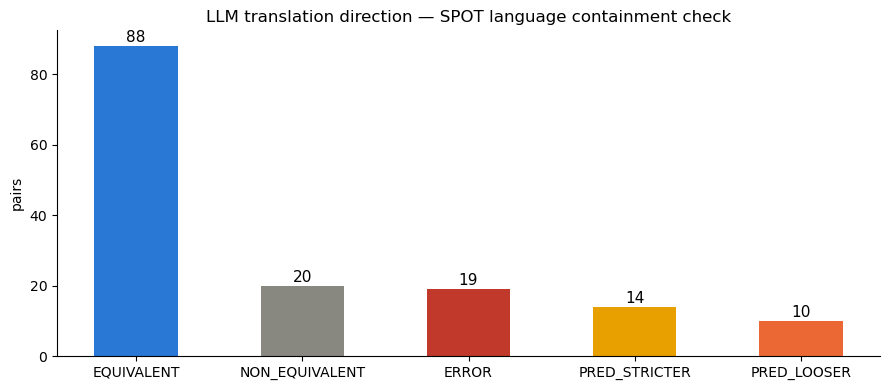


Interpretation:
  EQUIVALENT     — LLM got it right structurally
  PRED_LOOSER    — LLM under-constrained (too permissive)
  PRED_STRICTER  — LLM over-constrained (too restrictive)
  NON_EQUIVALENT — LLM produced structurally unrelated formula


In [7]:
import matplotlib.pyplot as plt

counts = direction_df['verdict'].value_counts()
colors = {
    'EQUIVALENT':     '#2a78d6',
    'PRED_LOOSER':    '#eb6834',
    'PRED_STRICTER':  '#e8a000',
    'NON_EQUIVALENT': '#888780',
    'ERROR':          '#c0392b',
    'SKIP':           '#bdc3c7',
}

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(counts.index, counts.values,
              color=[colors.get(k, 'grey') for k in counts.index],
              width=0.5, edgecolor='none')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            str(val), ha='center', va='bottom', fontsize=11)
ax.set_title('LLM translation direction — SPOT language containment check', fontsize=12)
ax.set_ylabel('pairs')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

print('\nInterpretation:')
print('  EQUIVALENT     — LLM got it right structurally')
print('  PRED_LOOSER    — LLM under-constrained (too permissive)')
print('  PRED_STRICTER  — LLM over-constrained (too restrictive)')
print('  NON_EQUIVALENT — LLM produced structurally unrelated formula')

## Part 6 — Next steps with FRET

To actually use FRET for dataset expansion, the options are:

**Option A — Use FRET's example projects directly**
- Clone the FRET repo and extract the JSON example files
- Each entry has: NL requirement (FRETish), generated LTL, component, scope
- These are well-structured NL→LTL pairs you can add to your benchmark

**Option B — Generate new pairs via FRETish grammar**
- Write your own FRETish requirements for robotics scenarios
- Run them through FRET's formula generator (Node.js CLI)
- Get verified NL→LTL pairs as ground truth for new benchmark instances

**Option C — Use FRET's LTL output as reference formulas**
- Take existing NL requirements from your benchmark
- Reformulate them in FRETish
- Use FRET's LTL output as an alternative gold standard alongside your existing φ*

**Recommendation for your project:**
Option A is the quickest path to dataset expansion.
FRET ships several aerospace/robotics example projects with hundreds of requirements.
These map directly to the robotics domain of your existing benchmark.